# Image Processing Basics with OpenCV

Reading images, grayscale conversion, convolution, edge detection and bounding boxes, plus how to prepare an image for an AI model.

**Pipeline:** read, grayscale, convolution, edge detection, bounding boxes, AI preprocessing

**Requirements:** `pip install opencv-python numpy matplotlib`

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(images, titles, cols=3, figsize=(15, 5), cmap=None):
    """Display images inline. Handles BGR (3-channel) and grayscale (2D) arrays."""
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(figsize[0], figsize[1] * rows))
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))   # matplotlib expects RGB
        else:
            plt.imshow(im, cmap="gray")
        plt.title(t); plt.axis("off")
    plt.tight_layout(); plt.show()


OpenCV version: 4.11.0


## 1. Read an image

OpenCV loads images as NumPy arrays of shape `(height, width, channels)` in **BGR** order (not RGB), dtype `uint8` (0-255).
Set `IMAGE_PATH` to your own file, or leave it as `None` to use a generated demo image.

Shape (H, W, C): (400, 600, 3) | dtype: uint8
Pixel at (0,0) [B, G, R]: [235 235 235]


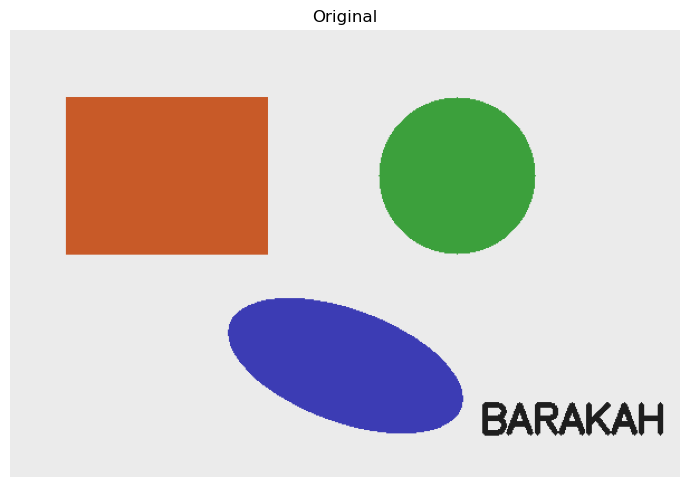

In [10]:
IMAGE_PATH = None   # e.g. "photo.jpg"

def load_image(path=None):
    if path:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Could not read image: {path}")
        return img
    # Synthetic demo image
    img = np.full((400, 600, 3), 235, np.uint8)
    cv2.rectangle(img, (50, 60), (230, 200), (40, 90, 200), -1)
    cv2.circle(img, (400, 130), 70, (60, 160, 60), -1)
    cv2.ellipse(img, (300, 300), (110, 50), 20, 0, 360, (180, 60, 60), -1)
    cv2.putText(img, "BARAKAH TECHLAB", (420, 360), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (30, 30, 30), 3)
    return img

img = load_image(IMAGE_PATH)
print("Shape (H, W, C):", img.shape, "| dtype:", img.dtype)
print("Pixel at (0,0) [B, G, R]:", img[0, 0])
show([img], ["Original"], cols=1, figsize=(7, 5))

## 2. Grayscale conversion

A weighted sum of the channels (green weighs most because human vision is most sensitive to it):

$$Y = 0.299\,R + 0.587\,G + 0.114\,B$$

Max difference between cv2 and manual: 0


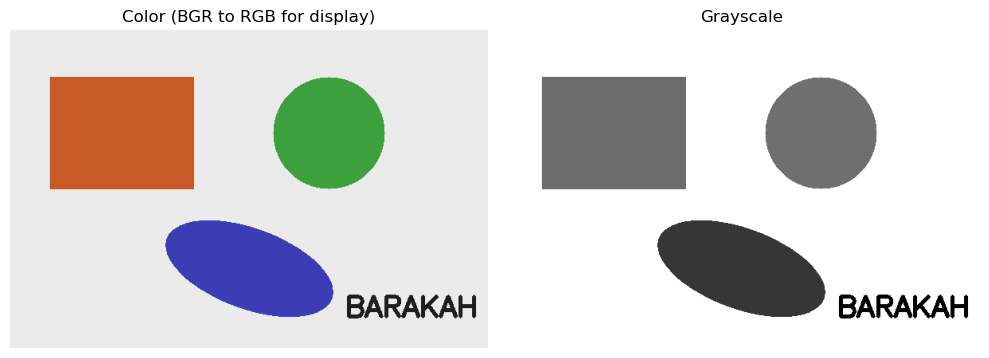

In [11]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Same formula by hand
b, g, r = img[..., 0], img[..., 1], img[..., 2]
gray_manual = (0.299 * r + 0.587 * g + 0.114 * b).round().astype(np.uint8)

print("Max difference between cv2 and manual:", np.abs(gray.astype(int) - gray_manual.astype(int)).max())
show([img, gray], ["Color (BGR to RGB for display)", "Grayscale"], cols=2, figsize=(10, 4))

## 3. The mathematics of convolution

For an image $I$ and kernel $K$ of size $(2a+1)\times(2b+1)$:

$$(I * K)(y,x) = \sum_{i=-a}^{a}\sum_{j=-b}^{b} K(i,j)\; I(y-i,\,x-j)$$

At every pixel, multiply the kernel with the pixels under it and sum into **one** number.

- Strict convolution **flips** the kernel; cross-correlation does not. OpenCV's `filter2D` and deep-learning libraries use cross-correlation. For symmetric kernels they are identical.
- Output size for input $n$, kernel $k$, padding $p$, stride $s$: $\lfloor (n+2p-k)/s \rfloor + 1$

| Kernel | Matrix | Effect |
|---|---|---|
| Box blur | all entries $1/9$ | Averages neighbors; weights sum to 1, so brightness is preserved |
| Sharpen | `[[0,-1,0],[-1,5,-1],[0,-1,0]]` | Boosts the center, subtracts neighbors |
| Sobel-X | `[[-1,0,1],[-2,0,2],[-1,0,1]]` | Approximates $\partial I/\partial x$; weights sum to 0, so flat areas give 0 |
| Sobel-Y | `[[-1,-2,-1],[0,0,0],[1,2,1]]` | Approximates $\partial I/\partial y$ |

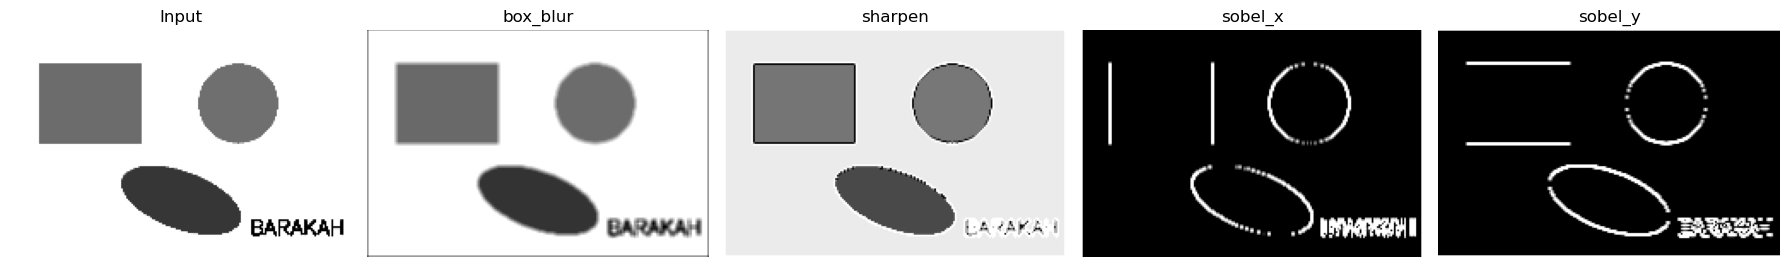

In [12]:
def convolve2d(image, kernel):
    # Naive 2D convolution with zero padding and 'same' output size.
    kernel = np.flipud(np.fliplr(kernel)).astype(np.float32)   # flip = true convolution
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(image.astype(np.float32), ((ph, ph), (pw, pw)))
    out = np.zeros(image.shape, np.float32)
    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            out[y, x] = np.sum(padded[y:y + kh, x:x + kw] * kernel)
    return out

KERNELS = {
    "box_blur": np.ones((3, 3), np.float32) / 9.0,
    "sharpen":  np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32),
    "sobel_x":  np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
    "sobel_y":  np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32),
}

small = cv2.resize(gray, (200, 133))     # small image: the Python loop is slow
results = {name: convolve2d(small, k) for name, k in KERNELS.items()}

show([small] + [np.clip(np.abs(v), 0, 255).astype(np.uint8) for v in results.values()],
     ["Input"] + list(results.keys()), cols=5, figsize=(18, 3))

### Verify against OpenCV

`cv2.filter2D` is the optimized version. We flip the kernel ourselves so its cross-correlation becomes true convolution.

In [13]:
k = KERNELS["sobel_x"]
cv_out = cv2.filter2D(small.astype(np.float32), -1, np.flipud(np.fliplr(k)),
                      borderType=cv2.BORDER_CONSTANT)
print("Manual convolution matches OpenCV:", np.allclose(results["sobel_x"], cv_out, atol=1e-3))

Manual convolution matches OpenCV: True


## 4. Edge detection

Gradient magnitude and direction from the two Sobel responses $G_x, G_y$:

$$|\nabla I| = \sqrt{G_x^2 + G_y^2}, \qquad \theta = \operatorname{atan2}(G_y, G_x)$$

**Canny** adds Gaussian blur, non-maximum suppression (thin edges to 1 px) and hysteresis thresholding
(keep pixels above `high`, plus pixels above `low` that connect to a strong edge).

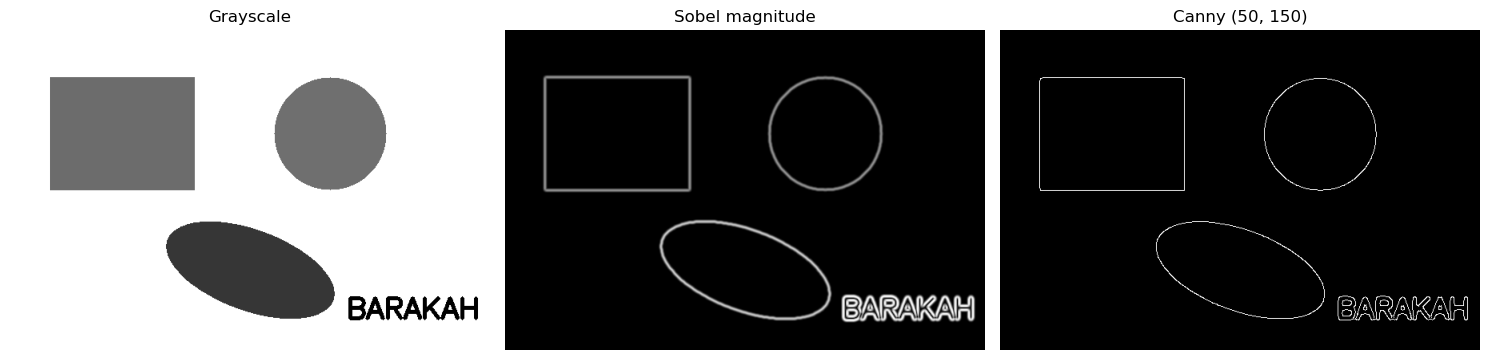

In [14]:
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

gx = cv2.Sobel(blur, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(blur, cv2.CV_32F, 0, 1, ksize=3)
magnitude = cv2.normalize(cv2.magnitude(gx, gy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

canny = cv2.Canny(blur, 50, 150)

show([gray, magnitude, canny], ["Grayscale", "Sobel magnitude", "Canny (50, 150)"])

## 5. Bounding boxes

Close small gaps in the edge map with a morphological operation, find outer contours, then take the axis-aligned rectangle of each one.

Detected 4 objects (x, y, w, h):
   (422, 332, 163, 31)
   (195, 239, 211, 122)
   (330, 60, 141, 141)
   (49, 59, 182, 142)


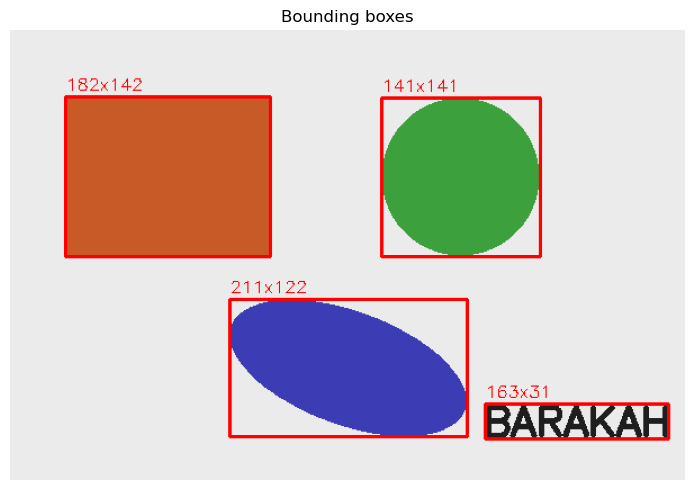

In [15]:
def draw_bounding_boxes(image, edges, min_area=500):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    annotated, boxes = image.copy(), []
    for c in contours:
        if cv2.contourArea(c) < min_area:      # ignore tiny noise
            continue
        x, y, w, h = cv2.boundingRect(c)
        boxes.append((x, y, w, h))
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 0, 255), 2)
        cv2.putText(annotated, f"{w}x{h}", (x, max(y - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    return annotated, boxes

annotated, boxes = draw_bounding_boxes(img, canny)
print(f"Detected {len(boxes)} objects (x, y, w, h):")
for b in boxes:
    print("  ", b)
show([annotated], ["Bounding boxes"], cols=1, figsize=(8, 5))

## 6. Prepare the image for an AI model

1. BGR to RGB
2. Resize to the model input size (e.g. 224x224)
3. Scale to $[0,1]$
4. Normalize per channel: $x' = (x - \mu)/\sigma$ (ImageNet statistics)
5. Reorder HWC to CHW and add a batch dimension

In [16]:
def preprocess_for_model(image, size=(224, 224)):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, size, interpolation=cv2.INTER_AREA)
    x = rgb.astype(np.float32) / 255.0
    mean = np.array([0.485, 0.456, 0.406], np.float32)
    std = np.array([0.229, 0.224, 0.225], np.float32)
    x = (x - mean) / std
    return np.transpose(x, (2, 0, 1))[None, ...]     # (1, 3, H, W)

tensor = preprocess_for_model(img)
print("Tensor shape:", tensor.shape, "| dtype:", tensor.dtype)
print(f"Value range: [{tensor.min():.2f}, {tensor.max():.2f}]")

Tensor shape: (1, 3, 224, 224) | dtype: float32
Value range: [-1.60, 2.29]


## Summary

| Step | Key function | Why it matters |
|---|---|---|
| Read | `cv2.imread` | Remember the BGR order |
| Grayscale | `cv2.cvtColor` | Reduces data, keeps structure |
| Convolution | `cv2.filter2D` | The same operation CNN layers learn |
| Edges | `cv2.Sobel`, `cv2.Canny` | Gradient-based structure |
| Boxes | `cv2.findContours`, `cv2.boundingRect` | Object localization |
| AI prep | resize, normalize, CHW | Required input format for models |